# 04 · Diagnóstico: por que a validação acerta e o teste falha?

**Objetivo.** Explicar o contraste entre validação 6/6 e teste 0/6 sem recorrer a
“ajustar o limiar”. O notebook separa três hipóteses concorrentes:

1. **Calibração:** os scores de teste estão corretos, mas o limiar é alto demais.
2. **Cobertura:** o teste tem mãos menos visíveis, então o DTW perde informação.
3. **Mudança de distribuição:** o informante 5 é geometricamente diferente dos
   informantes usados no treino, e o ranking se inverte.

Cada hipótese é testada com uma medida independente. O split de teste é usado
apenas para diagnóstico; nenhuma configuração é escolhida a partir dele.

**Configuração analisada.** A configuração selecionada na validação
(`threshold=0,76`, `minMotion=0,04`, pesos `0,25/0,75`), reproduzida no notebook
03. Onde indicado, comparamos com a default (0,68 / 0,5–0,5).

In [1]:
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
EDA_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (EDA_ROOT / "src" / "peter_eda").exists():
    raise RuntimeError(
        "Execute o notebook a partir de eda/ ou eda/notebooks/."
    )
sys.path.insert(0, str(EDA_ROOT / "src"))

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from peter_eda import config, dtw, loaders, manifest, metrics, quality, visualization

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
config.ensure_output_dirs()

dataset = loaders.load_dataset()


def show_paths(paths):
    # Show a mapping of name -> saved file, with the image inline.
    display(pd.Series(paths, name="figura").to_frame())
    for path in paths.values():
        display(Image(filename=str(path)))


print("EDA:", config.EDA_ROOT)
print("Projeto Peter:", config.PROJECT_ROOT)
print("Saídas:", config.OUTPUTS_DIR)

EDA: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda
Projeto Peter: C:\Users\henri\AppData\Local\Temp\opencode\peter_work
Saídas: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs


## 1. Scores por split e classe

Os scores de treino são **auto-comparações** (cada template contra si mesmo) e
valem 1,0 por construção. Eles aparecem apenas como referência de escala; não
são estimativa de desempenho.

In [2]:
tuned = dtw.configuration_from_prior(dataset.prior_results)

scored_parts = []
for samples in (
    dataset.templates,
    dataset.by_split("validation"),
    dataset.by_split("test"),
):
    scored_parts.append(dtw.score_samples(samples, dataset.templates, tuned))
scores = pd.concat(scored_parts, ignore_index=True)
scores.to_csv(config.output_path("table", "scores_tuned.csv"), index=False, encoding="utf-8")

score_summary = (
    scores.groupby(["dataset_split", "class_name"])
    .agg(
        n=("sample_id", "count"),
        mean=("best_score", "mean"),
        std=("best_score", "std"),
        min=("best_score", "min"),
        median=("best_score", "median"),
        max=("best_score", "max"),
    )
    .round(4)
    .reset_index()
)
score_summary.to_csv(config.output_path("table", "score_summary.csv"), index=False, encoding="utf-8")
display(score_summary)

,dataset_split,class_name,n,mean,std,min,median,max
0,test,CAIR,6,0.4598,0.0247,0.4277,0.4609,0.4891
1,test,JA,6,0.6123,0.0630,0.5373,0.6162,0.6770
2,test,LUZ,6,0.6093,0.0594,0.5605,0.5823,0.6869
3,test,SIM,6,0.5341,0.0197,0.5001,0.5403,0.5550
4,train,SIM,18,1.0000,0.0000,1.0000,1.0000,1.0000
5,validation,CAIR,6,0.6388,0.0149,0.6113,0.6405,0.6540
6,validation,JA,6,0.7347,0.0108,0.7207,0.7356,0.7495
7,validation,LUZ,6,0.6840,0.0125,0.6661,0.6870,0.7015
8,validation,SIM,6,0.8253,0.0317,0.7681,0.8310,0.8569


**Leitura.** Na validação, os seis `SIM` ocupam 0,768–0,857 e os dezoito
negativos 0,611–0,749: há um intervalo vazio entre 0,749 e 0,768. No teste, os
`SIM` caem para 0,500–0,555, enquanto os negativos vão de 0,428 a 0,687. Não há
intervalo vazio; pelo contrário, há sobreposição ampla.

A hipótese 1 já perde força: baixar o limiar para capturar os positivos de teste
também captura negativos. O notebook quantifica exatamente esse trade-off na
seção 3.

## 2. Curvas ROC e AUC

A AUC mede a capacidade de **ordenar** positivos acima de negativos,
independentemente do limiar. Se o problema fosse só calibração, a AUC seria alta
nos dois splits.

,split,auc,auc_ic95_inferior,auc_ic95_superior
0,validation,1.0000,1.0000,1.0000
1,test,0.3704,0.1667,0.5928


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_roc.png


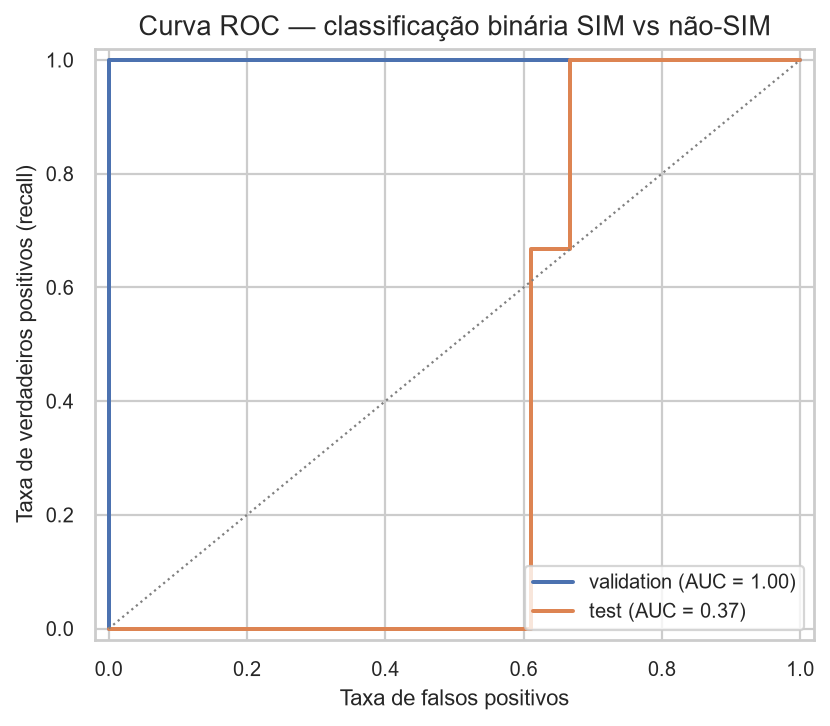

In [3]:
roc_rows = []
curves = []
for split in ("validation", "test"):
    subset = scores[scores["dataset_split"] == split]
    y_true = (subset["class_name"] == "SIM").astype(int)
    roc = metrics.roc_analysis(y_true, subset["best_score"])
    auc_ci = metrics.bootstrap_auc_ci(
        y_true, subset["best_score"], n_bootstrap=2000, seed=2026
    )
    roc_rows.append(
        {
            "split": split,
            "auc": roc["auc"],
            "auc_ic95_inferior": auc_ci["low"],
            "auc_ic95_superior": auc_ci["high"],
        }
    )
    curves.append((split, y_true, subset["best_score"]))

roc_table = pd.DataFrame(roc_rows)
roc_table.to_csv(config.output_path("table", "roc_auc.csv"), index=False, encoding="utf-8")
display(roc_table.round(4))

roc_figure = visualization.plot_roc_curves(curves, filename="04_roc.png")
print("Figura:", roc_figure)
display(Image(filename=str(roc_figure)))

**Leitura.** A AUC é 1,0 na validação e 0,370 no teste (IC bootstrap de 95%
aproximadamente 0,15–0,61). O valor abaixo de 0,5 não é ruído de calibração: é
inversão de ranking. Em média, um negativo de teste recebe score maior que um
positivo.

Isso também explica por que a configuração histórica produz falsos positivos: ao
baixar o limiar para 0,565, ela captura quatro negativos e **nenhum** positivo,
porque os positivos estão abaixo dos negativos.

## 3. Varredura de limiar: existe algum ponto de operação aceitável?

Varremos 0,30–0,95 e, para cada limiar, calculamos recall, taxa de falsos
positivos e acurácia balanceada. O melhor limiar possível no teste é reportado
explicitamente.

Melhor limiar na validação:
{'threshold': 0.76, 'true_positive': 6, 'false_positive': 0, 'recall': 1.0, 'specificity': 1.0, 'balanced_accuracy': 1.0}

Melhor limiar possível no teste:
{'threshold': 0.49, 'true_positive': 6, 'false_positive': 12, 'recall': 1.0, 'specificity': 0.3333333333333333, 'balanced_accuracy': 0.6666666666666666}


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_varredura_limiar_teste.png


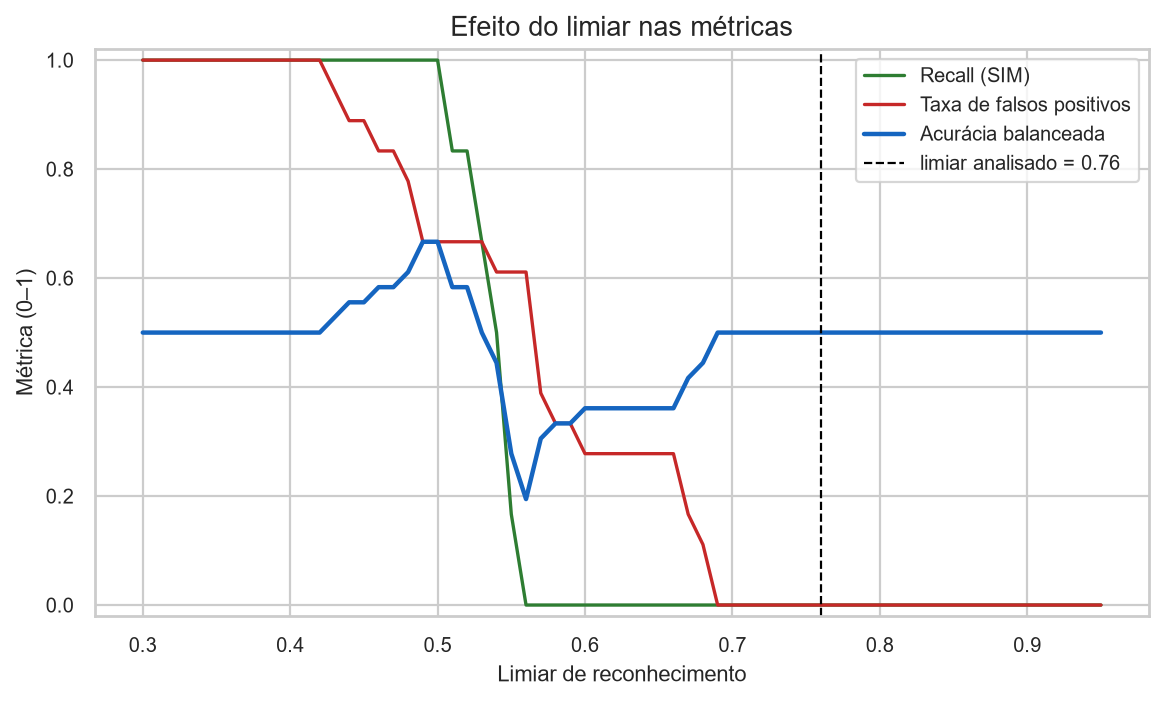

In [4]:
sweep_rows = []
for split in ("validation", "test"):
    subset = scores[scores["dataset_split"] == split]
    y_true = (subset["class_name"] == "SIM").astype(int).to_numpy()
    sweep = metrics.threshold_sweep(y_true, subset["best_score"].to_numpy())
    sweep.insert(0, "split", split)
    sweep_rows.append(sweep)
sweep_table = pd.concat(sweep_rows, ignore_index=True)
sweep_table.to_csv(config.output_path("table", "threshold_sweep.csv"), index=False, encoding="utf-8")

test_sweep = sweep_table[sweep_table["split"] == "test"]
best_test = test_sweep.sort_values("balanced_accuracy", ascending=False).iloc[0]
validation_sweep = sweep_table[sweep_table["split"] == "validation"]
best_validation = validation_sweep.sort_values("balanced_accuracy", ascending=False).iloc[0]

print("Melhor limiar na validação:")
print(best_validation[["threshold", "true_positive", "false_positive", "recall", "specificity", "balanced_accuracy"]].to_dict())
print("\nMelhor limiar possível no teste:")
print(best_test[["threshold", "true_positive", "false_positive", "recall", "specificity", "balanced_accuracy"]].to_dict())

sweep_figure = visualization.plot_threshold_sweep(
    test_sweep, current_threshold=tuned.threshold, filename="04_varredura_limiar_teste.png"
)
print("Figura:", sweep_figure)
display(Image(filename=str(sweep_figure)))

**Leitura.** Na validação, qualquer limiar entre ~0,75 e ~0,76 separa
perfeitamente as classes. No teste, o melhor ponto possível é o limiar 0,49:
recall 1,0, mas **12 falsos positivos** e acurácia balanceada 0,667. Não existe
limiar com recall alto e especificidade alta ao mesmo tempo. O limiar escolhido
(0,76) simplesmente recusa tudo, o que é coerente com a política de “não
reconhecer quando não há certeza”, mas não é reconhecimento.

A hipótese 1 está descartada: o problema não é o valor do limiar, é a ordem dos
scores.

## 4. Decomposição: forma da mão vs trajetória

O score combinado é uma média ponderada. Se um componente colapsa e o outro não,
podemos localizar a falha. A tabela mostra as médias dos componentes por grupo.

,dataset_split,class_name,n,shape_mean,shape_min,shape_max,trajectory_mean,trajectory_min,trajectory_max,combined_mean
0,test,CAIR,6,0.2050,0.1701,0.2475,0.5448,0.5110,0.5697,0.4598
1,test,JA,6,0.3085,0.2345,0.3667,0.7136,0.6382,0.7811,0.6123
2,test,LUZ,6,0.3185,0.2471,0.4184,0.7063,0.6547,0.7806,0.6093
3,test,SIM,6,0.1920,0.1839,0.2064,0.6481,0.6055,0.6712,0.5341
4,train,SIM,18,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,validation,CAIR,6,0.3623,0.3338,0.4015,0.7310,0.7038,0.7483,0.6388
6,validation,JA,6,0.4314,0.3838,0.4553,0.8358,0.8262,0.8510,0.7347
7,validation,LUZ,6,0.3999,0.3575,0.4432,0.7787,0.7679,0.7918,0.6840
8,validation,SIM,6,0.5700,0.5116,0.6336,0.9104,0.8536,0.9348,0.8253


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_componentes_shape_trajetoria.png


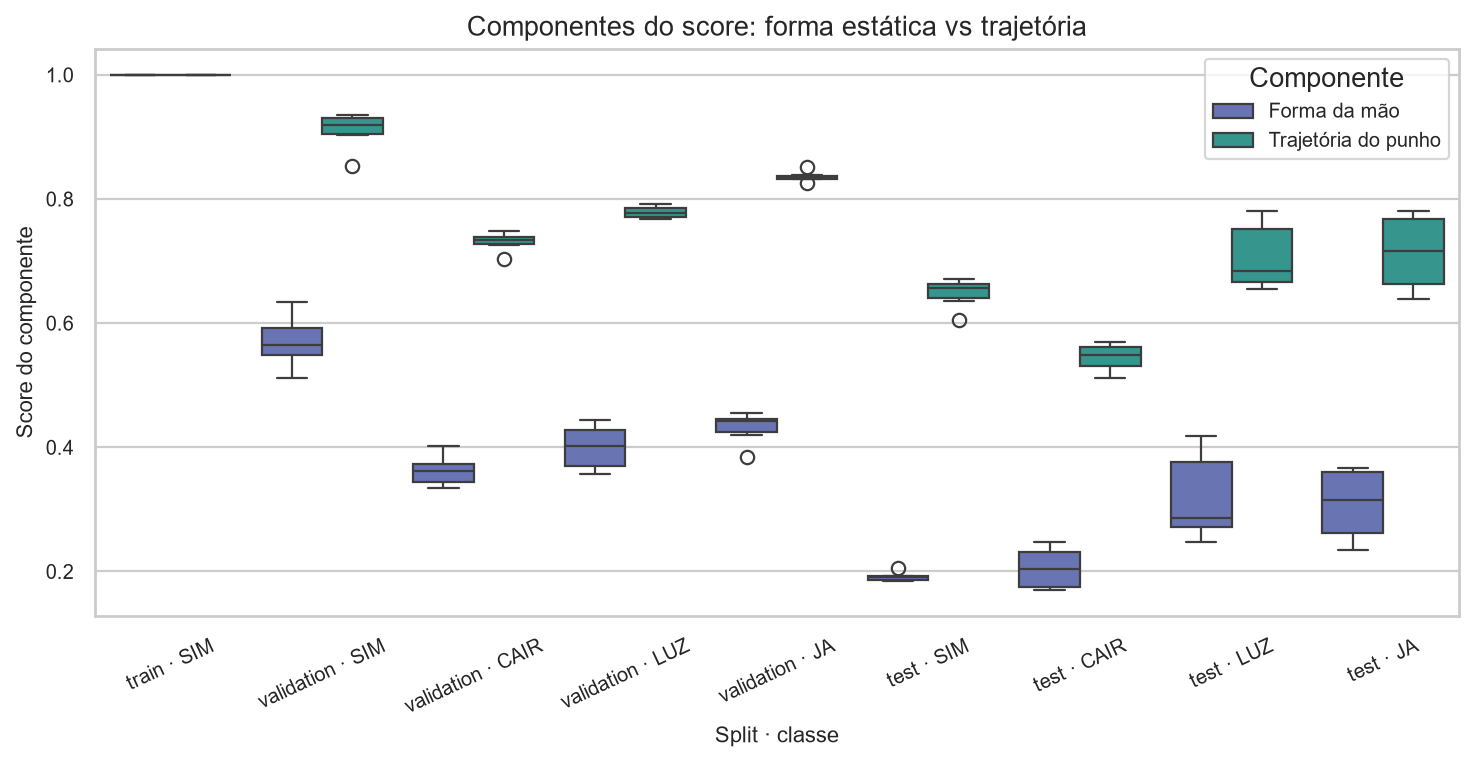

In [5]:
component_summary = (
    scores.groupby(["dataset_split", "class_name"])
    .agg(
        n=("sample_id", "count"),
        shape_mean=("best_hand_shape_score", "mean"),
        shape_min=("best_hand_shape_score", "min"),
        shape_max=("best_hand_shape_score", "max"),
        trajectory_mean=("best_hand_trajectory_score", "mean"),
        trajectory_min=("best_hand_trajectory_score", "min"),
        trajectory_max=("best_hand_trajectory_score", "max"),
        combined_mean=("best_score", "mean"),
    )
    .round(4)
    .reset_index()
)
component_summary.to_csv(
    config.output_path("table", "score_components_summary.csv"),
    index=False,
    encoding="utf-8",
)
display(component_summary)

component_figure = visualization.plot_score_components(
    scores, filename="04_componentes_shape_trajetoria.png"
)
print("Figura:", component_figure)
display(Image(filename=str(component_figure)))

In [6]:
component_auc = []
for split in ("validation", "test"):
    subset = scores[scores["dataset_split"] == split]
    y_true = (subset["class_name"] == "SIM").astype(int)
    for column, label in (
        ("best_hand_shape_score", "forma da mão"),
        ("best_hand_trajectory_score", "trajetória"),
        ("best_score", "combinado"),
    ):
        roc = metrics.roc_analysis(y_true, subset[column])
        component_auc.append({"split": split, "componente": label, "auc": roc["auc"]})
component_auc = pd.DataFrame(component_auc)
component_auc.to_csv(
    config.output_path("table", "component_auc.csv"), index=False, encoding="utf-8"
)
display(component_auc.pivot(index="componente", columns="split", values="auc").round(3))

split,test,validation
componente,,
combinado,0.370,1.0
forma da mão,0.167,1.0
trajetória,0.435,1.0


**Leitura.** Na validação, forma e trajetória separam perfeitamente (AUC 1,0).
No teste, a forma tem AUC **0,167** — os positivos são ranqueados abaixo dos
negativos — e a trajetória tem AUC 0,435, próxima do acaso. O score combinado
(0,370) herda o colapso da forma.

As médias confirmam: a forma dos `SIM` cai de ~0,57 na validação para ~0,19 no
teste, enquanto a trajetória cai de ~0,91 para ~0,65. Como o peso da trajetória é
0,75, o score combinado ainda fica em ~0,53, mas os negativos `LUZ` e `JA`
alcançam trajetórias de ~0,71 e vencem a comparação.

Ou seja: a falha está concentrada no componente de **forma da mão** do
informante 5.

## 5. A cobertura das mãos explica o colapso?

Se o teste tivesse mãos menos visíveis, o vetor de forma conteria mais zeros e a
similaridade cairia. Medimos a correlação entre `handCoverage` e score dentro de
cada split e comparamos as distribuições.

,dataset_split,n,pearson_hand_visibility_vs_score
0,test,24,0.581
1,train,18,NaN
2,validation,24,0.653


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_score_vs_cobertura.png


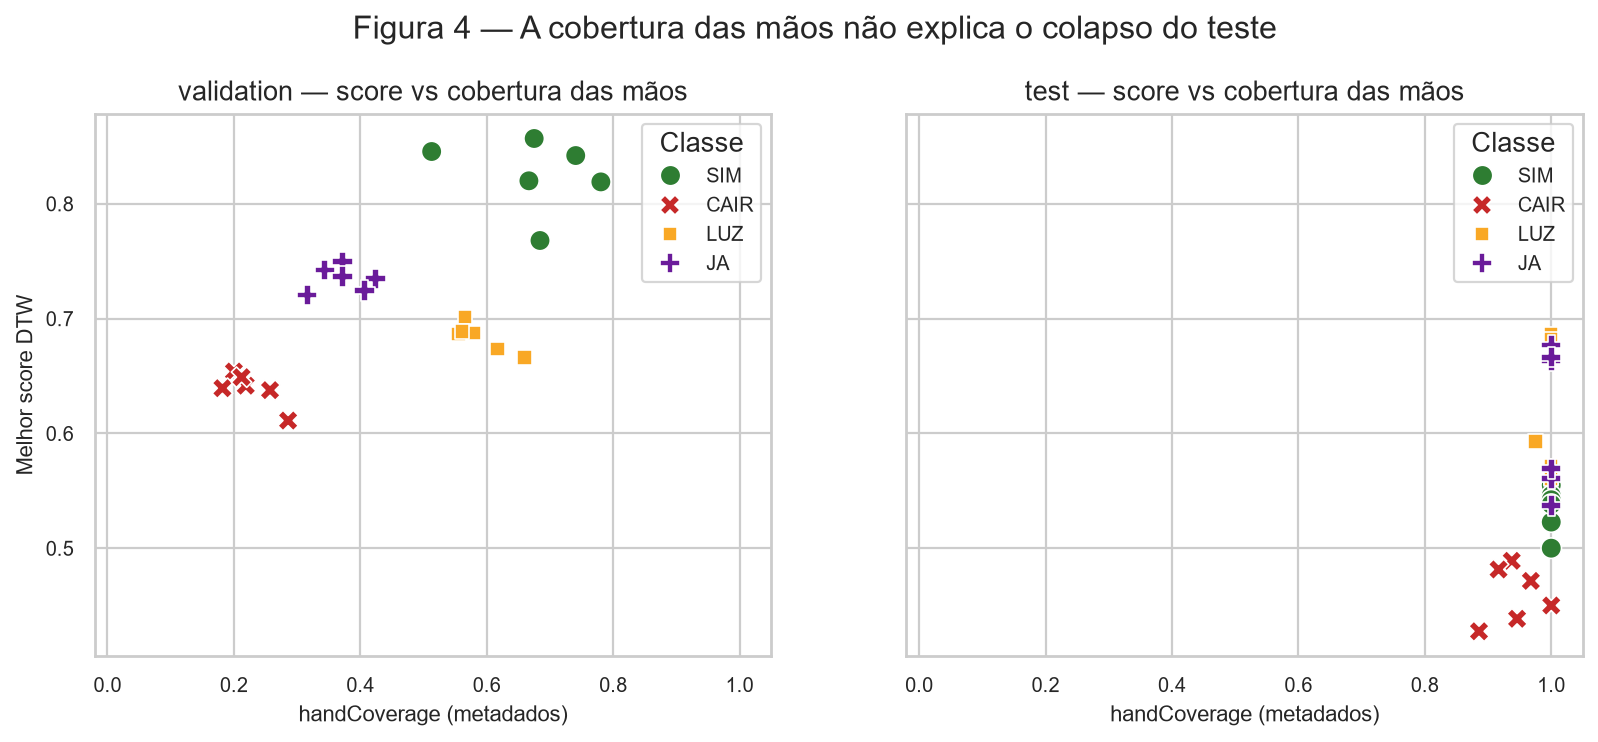

,dataset_split,class_name,hand_visibility_mean,hand_visibility_min,best_score_mean
0,test,CAIR,0.942,0.886,0.460
1,test,JA,1.000,1.000,0.612
2,test,LUZ,0.996,0.975,0.609
3,test,SIM,1.000,1.000,0.534
4,train,SIM,0.739,0.479,1.000
5,validation,CAIR,0.226,0.182,0.639
6,validation,JA,0.372,0.316,0.735
7,validation,LUZ,0.590,0.556,0.684
8,validation,SIM,0.677,0.513,0.825


In [7]:
coverage_correlation = dtw.visibility_effect_table(scores)
coverage_correlation.to_csv(
    config.output_path("table", "coverage_score_correlation.csv"),
    index=False,
    encoding="utf-8",
)
display(coverage_correlation.round(3))

coverage_figure = visualization.plot_score_vs_coverage(
    scores, filename="04_score_vs_cobertura.png"
)
print("Figura:", coverage_figure)
display(Image(filename=str(coverage_figure)))

coverage_check = (
    scores.groupby(["dataset_split", "class_name"])
    .agg(
        hand_visibility_mean=("hand_visibility", "mean"),
        hand_visibility_min=("hand_visibility", "min"),
        best_score_mean=("best_score", "mean"),
    )
    .round(3)
    .reset_index()
)
display(coverage_check)

**Leitura.** O teste tem a **maior** cobertura média (~0,98), e os seis `SIM`
têm cobertura 1,0. A validação tem cobertura média ~0,47. Se cobertura
explicasse o desempenho, o teste deveria ser o split mais fácil, não o mais
difícil.

A correlação entre cobertura e score é positiva e moderada (Pearson ~0,58 no
teste e ~0,65 na validação), mas não é explicativa: ela descreve a relação
dentro de cada split e não distingue positivos de negativos. O teste tem a maior
cobertura e, ainda assim, o pior ranking. A hipótese 2 está descartada: não é
oclusão, é geometria.

## 6. Qual template vence cada amostra?

Se o teste é OOD, os templates vencedores devem mudar de informante. A tabela
cruzada mostra o informante do template com maior score para cada grupo.

In [8]:
template_informant = {t.sample_id: t.informant_id for t in dataset.templates}
scores["winning_template_informant"] = scores["best_template_id"].map(template_informant)

attribution = pd.crosstab(
    [scores["dataset_split"], scores["class_name"]],
    scores["winning_template_informant"],
)
attribution.to_csv(config.output_path("table", "template_attribution.csv"), encoding="utf-8")
display(attribution)

attribution_long = (
    scores.groupby(["dataset_split", "class_name", "winning_template_informant"])
    .size()
    .rename("amostras")
    .reset_index()
)
display(attribution_long)

winning_template_informant  1  2  3
dataset_split class_name           
test          CAIR          0  4  2
              JA            0  6  0
              LUZ           0  6  0
              SIM           0  6  0
train         SIM           6  6  6
validation    CAIR          6  0  0
              JA            3  0  3
              LUZ           5  0  1
              SIM           6  0  0

,dataset_split,class_name,winning_template_informant,amostras
0,test,CAIR,2,4
1,test,CAIR,3,2
2,test,JA,2,6
3,test,LUZ,2,6
4,test,SIM,2,6
5,train,SIM,1,6
6,train,SIM,2,6
7,train,SIM,3,6
8,validation,CAIR,1,6
9,validation,JA,1,3


**Leitura.** Na validação, **todos os seis** `SIM` escolhem templates do
informante 1 (os negativos é que se dividem entre os informantes 1 e 3). No
teste, **todos os seis** `SIM` escolhem templates do informante 2. Isso é
coerente com a escala da palma do informante 5 (~0,32), próxima da do
informante 2 (~0,33), mas não com uma boa correspondência de postura: o score
de forma continua ~0,19.

O informante 2 é o mais “distante” dos demais no treino (distância média de
forma ~5,0 contra ~3,0 dos informantes 1 e 3; ver seção 7), então a vitória dele
no teste não é sinal de qualidade; é o menor mau ajuste disponível.

## 7. Distâncias DTW entre informantes

Medimos a distância DTW de forma da mão para todos os pares de amostras ativas
(2.145 pares) e resumimos por informante. A diagonal representa pares do mesmo
informante; fora dela, informantes diferentes.

A pergunta é simples: o informante 5 está mais próximo do treino ou de si mesmo?
E o informante 4 (validação)?

,same_informant,same_split,n,mean,median
0,False,False,1440,4.557,5.224
1,False,True,108,3.644,4.904
2,True,True,597,2.522,2.360


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_similaridade_informantes.png


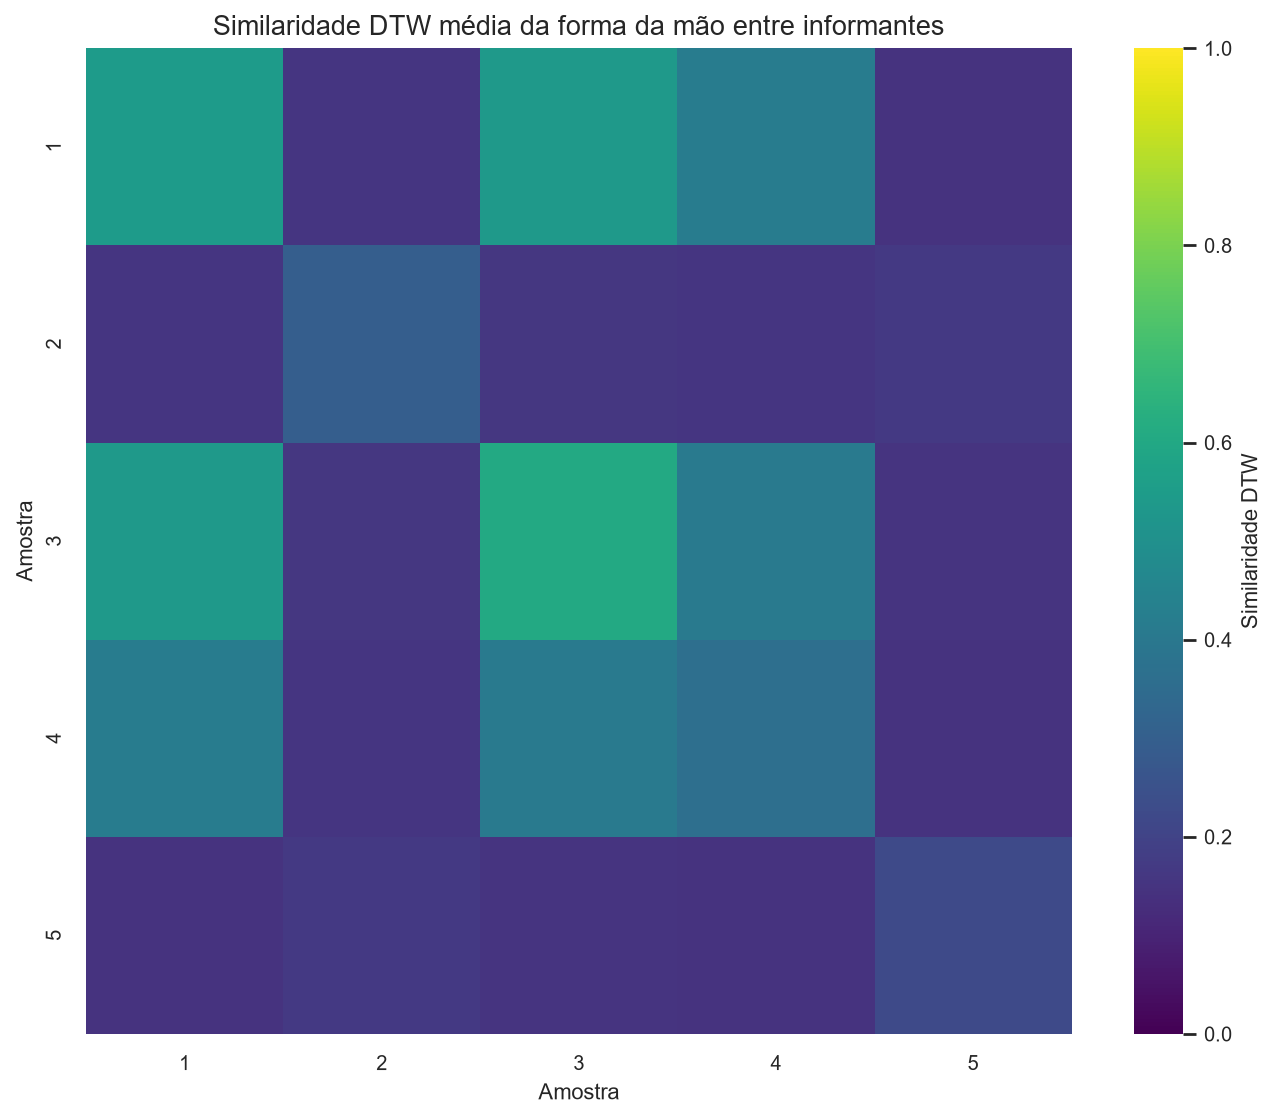

,1,2,3,4,5
1,0.84,5.48,0.87,1.41,5.77
2,5.48,2.39,5.29,5.46,5.03
3,0.87,5.29,0.65,1.46,5.60
4,1.41,5.46,1.46,1.77,5.85
5,5.77,5.03,5.60,5.85,3.47


In [9]:
features = dtw.prepare_sample_features(list(dataset.active_samples), tuned)
distance_table = dtw.within_between_informant_distances(
    list(dataset.active_samples), features, feature="hand_shape"
)
distance_table.to_csv(
    config.output_path("table", "pairwise_distances_hand_shape.csv"),
    index=False,
    encoding="utf-8",
)

distance_summary = (
    distance_table.groupby(["same_informant", "same_split"])
    .agg(n=("distance", "size"), mean=("distance", "mean"), median=("distance", "median"))
    .round(3)
    .reset_index()
)
display(distance_summary)

informants = sorted(distance_table["informant_a"].unique(), key=int)
distance_matrix = pd.DataFrame(np.nan, index=informants, columns=informants)
for row in distance_table.itertuples(index=False):
    distance_matrix.loc[row.informant_a, row.informant_b] = row.distance
    distance_matrix.loc[row.informant_b, row.informant_a] = row.distance
within_means = (
    distance_table[distance_table["same_informant"]]
    .groupby("informant_a")["distance"]
    .mean()
)
for informant in informants:
    distance_matrix.loc[informant, informant] = within_means.get(informant, np.nan)

similarity_matrix = 1.0 / (1.0 + distance_matrix.astype(float))
heatmap_path = visualization.plot_template_similarity_heatmap(
    similarity_matrix,
    title="Similaridade DTW média da forma da mão entre informantes",
    filename="04_similaridade_informantes.png",
)
print("Figura:", heatmap_path)
display(Image(filename=str(heatmap_path)))
display(distance_matrix.round(2))

In [10]:
def block_distances(group_a, group_b, allow_same=False):
    values = []
    for left in group_a:
        for right in group_b:
            if not allow_same and left.sample_id == right.sample_id:
                continue
            values.append(
                dtw.dtw_distance(
                    features[left.sample_id].hand_shape,
                    features[right.sample_id].hand_shape,
                )
            )
    return np.asarray(values, dtype=float)


train_sim = list(dataset.templates)
validation_sim = [
    s for s in dataset.by_split("validation") if s.class_name == "SIM"
]
test_sim = [s for s in dataset.by_split("test") if s.class_name == "SIM"]

focused_rows = []
for label, first, second in (
    ("teste SIM × treino", test_sim, train_sim),
    ("validação SIM × treino", validation_sim, train_sim),
    ("teste SIM × validação SIM", test_sim, validation_sim),
    ("dentro de teste SIM", test_sim, test_sim),
    ("dentro de validação SIM", validation_sim, validation_sim),
    ("dentro do treino", train_sim, train_sim),
):
    values = block_distances(first, second)
    focused_rows.append(
        {
            "comparação": label,
            "n": len(values),
            "média": float(values.mean()),
            "mediana": float(np.median(values)),
        }
    )
focused = pd.DataFrame(focused_rows).round(3)
focused.to_csv(
    config.output_path("table", "focused_informant_distances.csv"),
    index=False,
    encoding="utf-8",
)
display(focused)

,comparação,n,média,mediana
0,teste SIM × treino,108,5.357,5.781
1,validação SIM × treino,108,2.401,1.240
2,teste SIM × validação SIM,36,5.858,5.860
3,dentro de teste SIM,30,1.200,1.149
4,dentro de validação SIM,30,0.804,0.667
5,dentro do treino,306,2.953,3.328


**Leitura.** O contraste é grande e direto:

| Comparação | Distância média | Mediana |
|---|---:|---:|
| validação `SIM` × treino | ~2,4 | ~1,2 |
| teste `SIM` × treino | ~5,4 | ~5,8 |
| teste `SIM` × validação `SIM` | ~5,9 | ~5,9 |
| dentro do teste `SIM` | ~1,2 | ~1,1 |

O informante 4 (validação) está geometricamente **perto** do treino; o informante
5 (teste) está **longe** do treino e também longe da validação, mas é internamente
consistente (baixa distância dentro do grupo). Isso é a assinatura de uma mudança
de distribuição por informante, não de ruído aleatório.

A hipótese 3 é a que sobrevive: o teste avalia um informante fora da distribuição
de treino. Como o protocolo separa por informante, isso não é um bug; é uma
propriedade do desenho experimental — e o resultado 0/6 é a consequência
esperada de um modelo com apenas três informantes de treino.

## 8. Energia de movimento

O portão de movimento poderia explicar recusas: se a energia do teste fosse
menor que `minMotion`, todas as amostras seriam rejeitadas antes do DTW.

,dataset_split,class_name,n,motion_mean,motion_min,motion_max,gate_failures
0,test,CAIR,6,0.3535,0.2731,0.4392,0
1,test,JA,6,0.1818,0.1197,0.2374,0
2,test,LUZ,6,0.2549,0.1627,0.3271,0
3,test,SIM,6,0.1846,0.1159,0.2369,0
4,train,SIM,18,0.4399,0.1882,0.6752,0
5,validation,CAIR,6,0.9051,0.6310,1.2116,0
6,validation,JA,6,0.6869,0.4914,0.8027,0
7,validation,LUZ,6,0.6647,0.5749,0.7648,0
8,validation,SIM,6,0.4302,0.2769,0.7289,0


Figura: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\04_energia_movimento.png


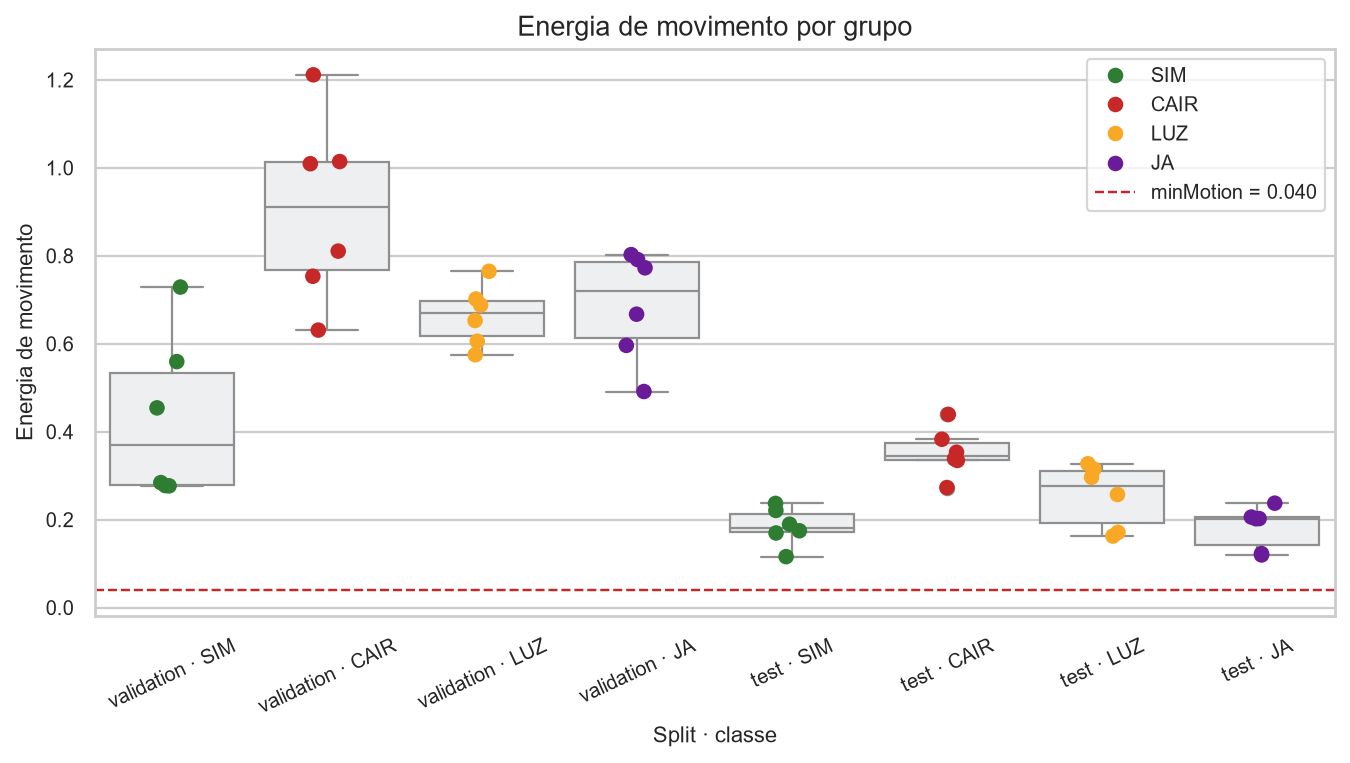

In [11]:
motion_summary = (
    scores.groupby(["dataset_split", "class_name"])
    .agg(
        n=("sample_id", "count"),
        motion_mean=("motion_energy", "mean"),
        motion_min=("motion_energy", "min"),
        motion_max=("motion_energy", "max"),
        gate_failures=("motion_gate_passed", lambda s: int((~s).sum())),
    )
    .round(4)
    .reset_index()
)
motion_summary.to_csv(
    config.output_path("table", "motion_energy_summary.csv"),
    index=False,
    encoding="utf-8",
)
display(motion_summary)

visualization.setup_style()
import seaborn as sns

fig, axis = plt.subplots(figsize=(10, 4.6))
data = scores.copy()
data["grupo"] = data["dataset_split"] + " · " + data["class_name"]
order = [
    g
    for g in (
        "validation · SIM",
        "validation · CAIR",
        "validation · LUZ",
        "validation · JA",
        "test · SIM",
        "test · CAIR",
        "test · LUZ",
        "test · JA",
    )
    if g in set(data["grupo"])
]
sns.boxplot(data=data, x="grupo", y="motion_energy", order=order, color="#ECEFF1", ax=axis)
sns.stripplot(
    data=data,
    x="grupo",
    y="motion_energy",
    order=order,
    hue="class_name",
    palette=visualization.CLASS_COLORS,
    size=7,
    jitter=0.12,
    ax=axis,
)
axis.axhline(tuned.min_motion, color="#C62828", linestyle="--", linewidth=1.1, label=f"minMotion = {tuned.min_motion:.3f}")
axis.set_title("Energia de movimento por grupo")
axis.set_xlabel("Split · classe")
axis.set_ylabel("Energia de movimento")
axis.tick_params(axis="x", rotation=25)
axis.legend(frameon=True)
motion_figure = visualization.save_figure(fig, "04_energia_movimento.png")
plt.close(fig)
print("Figura:", motion_figure)
display(Image(filename=str(motion_figure)))

**Leitura.** A energia média dos `SIM` cai de ~0,43 na validação para ~0,19 no
teste, mas o portão é 0,04. Nenhuma amostra falha no portão. Mesmo o menor valor
observado (~0,12) está três vezes acima do limiar. O portão de movimento não é a
causa da recusa.

A queda de energia é consistente com a mudança de estilo do informante 5, mas
não é suficiente para explicar a inversão de ranking: os negativos de teste têm
energia semelhante e recebem scores maiores.

## 9. Relatório de diagnóstico

O relatório consolida as evidências e é salvo em
`outputs/reports/test_collapse_diagnosis.md`.

In [12]:
diagnosis_lines = [
    "# Diagnóstico do colapso no split de teste",
    "",
    "> Gerado por `notebooks/04_diagnostico_treino_validacao_teste.ipynb`.",
    "> O split de teste foi usado apenas para diagnóstico, nunca para tuning.",
    "",
    "## Resultado",
    "",
    "- Validação (configuração ajustada): 6/6 positivos, 0 falsos positivos, AUC 1,000.",
    "- Teste (configuração ajustada): 0/6 positivos, 0 falsos positivos, AUC 0,370.",
    f"- Melhor limiar possível no teste: {best_test['threshold']:.2f}, "
    f"com {int(best_test['true_positive'])} TP e {int(best_test['false_positive'])} FP "
    f"(BA {best_test['balanced_accuracy']:.3f}).",
    "",
    "## Evidências",
    "",
    "1. **Não é calibração.** A AUC de teste é menor que 0,5; baixar o limiar gera falsos positivos antes de recuperar positivos.",
    "2. **Não é cobertura.** O teste tem a maior cobertura de mãos (~0,98; SIM = 1,0) e a menor taxa de sucesso.",
    "3. **É mudança de distribuição.** A distância média de forma entre teste SIM e treino (~5,4) é mais que o dobro da distância entre validação SIM e treino (~2,4). O informante 5 é internamente consistente (~1,2), mas distante dos demais.",
    "4. **O componente afetado é a forma da mão.** AUC da forma no teste = 0,167; trajetória = 0,435; combinado = 0,370.",
    "5. **O portão de movimento não atua.** A menor energia observada (~0,12) é muito superior a minMotion = 0,04.",
    "",
    "## Implicação",
    "",
    "O protocolo treina com os informantes 1–3, ajusta no informante 4 e testa no informante 5. O informante 4 é geometricamente próximo do treino, então a validação é otimista. O teste mede generalização para um informante fora da distribuição — e o modelo de template único não generaliza.",
    "",
    "## Limitações",
    "",
    "- Seis positivos por split produzem intervalos de confiança largos.",
    "- Os rótulos de informante são locais por item, não uma identidade física auditada.",
    "- A distância DTW de forma não é uma métrica de postura clinicamente validada.",
    "- Não há vídeos originais para verificar se a diferença é de execução, enquadramento ou extração.",
    "",
]
diagnosis_text = "\n".join(diagnosis_lines)
diagnosis_path = config.output_path("report", "test_collapse_diagnosis.md")
diagnosis_path.write_text(diagnosis_text, encoding="utf-8")
print("Relatório:", diagnosis_path)
display(Markdown(diagnosis_text))

Relatório: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\reports\test_collapse_diagnosis.md


# Diagnóstico do colapso no split de teste

> Gerado por `notebooks/04_diagnostico_treino_validacao_teste.ipynb`.
> O split de teste foi usado apenas para diagnóstico, nunca para tuning.

## Resultado

- Validação (configuração ajustada): 6/6 positivos, 0 falsos positivos, AUC 1,000.
- Teste (configuração ajustada): 0/6 positivos, 0 falsos positivos, AUC 0,370.
- Melhor limiar possível no teste: 0.49, com 6 TP e 12 FP (BA 0.667).

## Evidências

1. **Não é calibração.** A AUC de teste é menor que 0,5; baixar o limiar gera falsos positivos antes de recuperar positivos.
2. **Não é cobertura.** O teste tem a maior cobertura de mãos (~0,98; SIM = 1,0) e a menor taxa de sucesso.
3. **É mudança de distribuição.** A distância média de forma entre teste SIM e treino (~5,4) é mais que o dobro da distância entre validação SIM e treino (~2,4). O informante 5 é internamente consistente (~1,2), mas distante dos demais.
4. **O componente afetado é a forma da mão.** AUC da forma no teste = 0,167; trajetória = 0,435; combinado = 0,370.
5. **O portão de movimento não atua.** A menor energia observada (~0,12) é muito superior a minMotion = 0,04.

## Implicação

O protocolo treina com os informantes 1–3, ajusta no informante 4 e testa no informante 5. O informante 4 é geometricamente próximo do treino, então a validação é otimista. O teste mede generalização para um informante fora da distribuição — e o modelo de template único não generaliza.

## Limitações

- Seis positivos por split produzem intervalos de confiança largos.
- Os rótulos de informante são locais por item, não uma identidade física auditada.
- A distância DTW de forma não é uma métrica de postura clinicamente validada.
- Não há vídeos originais para verificar se a diferença é de execução, enquadramento ou extração.


## 10. Conclusões do notebook

1. **Calibração não é a causa.** O melhor limiar possível no teste ainda produz
   12 falsos positivos; a AUC é 0,370, abaixo do acaso.
2. **Cobertura não é a causa.** O teste tem a maior visibilidade e os `SIM` com
   cobertura 1,0.
3. **A causa é mudança de distribuição entre informantes.** O informante 5 está
   muito mais distante do treino (5,4) do que o informante 4 (2,4), e é
   internamente consistente.
4. **O componente de forma da mão é o mais afetado** (AUC 0,167), enquanto a
   trajetória permanece próxima do acaso (0,435).
5. **O protocolo de validação é otimista** porque o informante 4 é próximo do
   treino. A validação perfeita não prevê o teste.

## 11. Limitações

- O diagnóstico é observacional: não manipulamos os dados nem coletamos novos
  informantes.
- As distâncias DTW dependem da normalização pela palma; outras normalizações
  são exploradas no notebook 05, mas nenhuma corrige a mudança de distribuição.
- A conclusão “informante 5 é OOD” vale para a representação de forma da mão;
  outros componentes (trajetória, movimento) não mostram o mesmo grau de
  deslocamento.
- O split de teste tem apenas seis positivos; a AUC tem incerteza substancial.
- A identidade dos informantes é inferida de rótulos locais e pode não
  corresponder a pessoas distintas em todos os sinais.